# TV3 — LSTM và bằng chứng kiểm định theo từng hạng mục
        Bài toán:30 phiên adjusted close AAPL →1 hoặc5 giá tiếp theo. Notebook gọi module thật, không xây training loop riêng.
        **Mục1–5 đã nghiệm thu local; mục6 kiểm gói bàn giao trong notebook này. Chưa xác nhận máy người nhận hoặc checkpoint train AAPL.** Cấu hình hiện tại float64; không hạ precision TV2.
        Model trong minh họa là trọng số khởi tạo, không phải checkpoint đã train. Không dùng output dưới đây để tuyên bố độ chính xác hoặc gợi ý giao dịch.
        Tham chiếu `reports/audits/TV3_Progress.md`. Run All chạy lại suite tests và kiểm tra metadata/artifacts.

## Môi trường và nguồn dữ liệu

In [1]:
from pathlib import Path
import sys, json, os, subprocess, hashlib
from datetime import datetime, timezone
import importlib.metadata as packages
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'backend/data/preparation/snapshot.py').is_file())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
VERSION = 'aapl_2015_2025_acq_20261119T141302002415Z'
SCALER_DIR = ROOT/'artifacts/scalers/aapl_scaler_20261120T124720810874Z'
PREPARED_DIR = ROOT/'data/prepared/tv2_prepared_20261122T145943242978Z'
print('Executed UTC:', datetime.now(timezone.utc).isoformat())
print('Python:', sys.executable)
display(pd.DataFrame([{'package':n, 'version':packages.version(n)} for n in ['numpy','pandas','scikit-learn','torch','pytest']]))

def run_check(script, *args):
    env = dict(os.environ, OMP_NUM_THREADS='1', MKL_NUM_THREADS='1', PYTHONIOENCODING='utf-8')
    run = subprocess.run([sys.executable, '-X', 'utf8', str(ROOT/'scripts'/script), *args], cwd=ROOT, env=env, capture_output=True, text=True, encoding='utf-8')
    print(run.stdout)
    if run.returncode: raise RuntimeError(run.stderr or run.stdout)
    return json.loads(run.stdout)

Executed UTC: 2026-11-23T03:23:44.741779+00:00
Python: D:\learn_DeepLearning\Project_course-work\.venv\tv3_clean\Scripts\python.exe


,package,version
0,numpy,2.4.4
1,pandas,3.0.6
2,scikit-learn,1.9.1
3,torch,2.14.1
4,pytest,9.2.0


## 1. Source đúng module và kiến trúc
        Source tác giả được tiếp nhận vào backend/models và backend/model_trace. Bản GitHub nguyên trạng audit trước lỗi import; workspace này đã sửa bố trí. Sau đó đổi dtype mặc định64 theo lựa chọn người dùng.

In [2]:
import torch, inspect
from backend.models.lstm_one_step import LSTMOneStep
from backend.models.lstm_multi_step import LSTMMultiStep
torch.set_num_threads(1)
models={1:LSTMOneStep().eval(),5:LSTMMultiStep().eval()}
display(pd.DataFrame([{'model':type(m).__name__,'source':str(Path(inspect.getfile(type(m))).relative_to(ROOT)),'parameters':sum(p.numel() for p in m.parameters()),'weight_dtype':str(next(m.parameters()).dtype),'layers':m.lstm.num_layers,'hidden':m.lstm.hidden_size,'outputs':m.fc.out_features} for m in models.values()]))
print(models[1])

,model,source,parameters,weight_dtype,layers,hidden,outputs
0,LSTMOneStep,backend\models\lstm_one_step\model.py,4513,torch.float64,1,32,1
1,LSTMMultiStep,backend\models\lstm_multi_step\model.py,4645,torch.float64,1,32,5


LSTMOneStep(
  (lstm): LSTM(1, 32, batch_first=True)
  (fc): Linear(in_features=32, out_features=1, bias=True)
)


## 2. Kết nối với TV2 chính thức
        Accept snapshot/scaler/prepared bằng version/hash trước adapter. X/y CPU float64, shape giữ nguyên; model chỉ nhận X. Notebook không refit/scaler hoặc thay dữ liệu nguồn.

In [3]:
from backend.data.preparation.snapshot import load_tv1_snapshot
from backend.artifacts.scaler import load_scaler
from backend.artifacts.prepared import load_prepared_modes
snapshot = load_tv1_snapshot(ROOT, VERSION)
data = snapshot['data']
scaler, scaler_manifest = load_scaler(SCALER_DIR, expected_dataset_version=VERSION, expected_source_hashes=snapshot['acceptance']['hashes'])
modes, prepared_manifest = load_prepared_modes(PREPARED_DIR, expected_dataset_version=VERSION, expected_source_hashes=snapshot['acceptance']['hashes'], expected_scaler_id=scaler_manifest['scaler_id'])
assert snapshot['acceptance']['passed']
display(data.head())
print('Snapshot rows:', len(data), '| dates:', data.date.iloc[0], '→', data.date.iloc[-1])

,date,ticker,adjusted_close,dataset_version
0,2015-01-02,AAPL,24.153402,aapl_2015_2025_acq_20261119T141302002415Z
1,2015-01-05,AAPL,23.472971,aapl_2015_2025_acq_20261119T141302002415Z
2,2015-01-06,AAPL,23.475178,aapl_2015_2025_acq_20261119T141302002415Z
3,2015-01-07,AAPL,23.804344,aapl_2015_2025_acq_20261119T141302002415Z
4,2015-01-08,AAPL,24.718971,aapl_2015_2025_acq_20261119T141302002415Z


Snapshot rows: 2766 | dates: 2015-01-02 → 2025-12-31


In [4]:
from backend.data.preparation.tensors import make_lstm_inputs,make_lstm_training_batch
rows=[]
for h,result in modes.items():
    batch=result['splits']['val']
    packed=make_lstm_training_batch(batch,scaler,dataset_version=VERSION,forecast_length=h)
    only=make_lstm_inputs(batch['inputs'],scaler,dataset_version=VERSION,forecast_length=h)
    np.testing.assert_array_equal(packed['X'].numpy(),batch['X'])
    torch.testing.assert_close(only['X'],packed['X'],rtol=0,atol=0)
    with torch.no_grad(): prediction=models[h](only['X'][:2])
    rows.append({'mode':h,'samples':len(packed['X']),'X_shape':str(tuple(packed['X'].shape)),'y_shape':str(tuple(packed['y'].shape)),'dtype':str(packed['X'].dtype),'tensor_copy_max_difference':float(np.max(np.abs(packed['X'].numpy()-batch['X']))),'demo_output_shape':str(tuple(prediction.shape)),'finite':bool(torch.isfinite(prediction).all())})
display(pd.DataFrame(rows))
display(Markdown('Output shape/finite đạt chỉ chứng minh kết nối kỹ thuật; model chưa học từ AAPL.'))

,mode,samples,X_shape,y_shape,dtype,tensor_copy_max_difference,demo_output_shape,finite
0,1,250,"(250, 30, 1)","(250, 1)",torch.float64,0.0,"(2, 1)",True
1,5,246,"(246, 30, 1)","(246, 5)",torch.float64,0.0,"(2, 5)",True


Output shape/finite đạt chỉ chứng minh kết nối kỹ thuật; model chưa học từ AAPL.

### Quyết định dtype: giữ float64
        Dữ liệu/scaler/model/tensor đều64. Float64 giảm lỗi làm tròn nhưng không bảo đảm dự báo tốt hơn. Bảng dưới đọc phép đo CPU tổng hợp đã lưu, không phải thời gian train AAPL. Thread1, batch32,5 rounds×10 iterations; không đo lại khi Run All.

In [5]:
bench=json.loads((ROOT/'logs/audit/tv3_precision_20261123T022251223682Z/summary.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'model':r['model'],'forward32_ms':1000*r['measurements']['float32']['forward_median_seconds_per_batch'],'forward64_ms':1000*r['measurements']['float64']['forward_median_seconds_per_batch'],'Adam32_ms':1000*r['measurements']['float32']['adam_step_median_seconds_per_batch'],'Adam64_ms':1000*r['measurements']['float64']['adam_step_median_seconds_per_batch'],'weights64_bytes':r['parameter_bytes']['float64']} for r in bench['results']]))
print(bench['scope']); print(bench['limitations'])

,model,forward32_ms,forward64_ms,Adam32_ms,Adam64_ms,weights64_bytes
0,LSTMOneStep,0.54820,2.36850,3.83661,11.29208,36104
1,LSTMMultiStep,0.59284,2.05404,3.61363,11.30310,37160


Synthetic local CPU microbenchmark, randomized untrained base weights, no model selection or stock accuracy comparison.
Timing depends on CPU/backend/threads/load; parameter/input bytes exclude activations, gradients and Adam buffers. No guarantee float64 improves forecasting.


## 3. Nghiệm thu kiến trúc/state/gradient/lưu-nạp
        Chạy toàn bộ tests đang có và hiển thị từng case. Acceptance kiểm forward so LSTM→Linear, gradient sai phân số với mạng nhỏ hidden2/T3, backward mặc định hidden32, h/c zero mới, batch ordering, Adam smoke, file state_dict roundtrip và trọng số hai mode độc lập.
        Tests dùng dữ liệu tổng hợp; state_dict tạm không là checkpoint nghiên cứu. Không chứng minh optimizer hội tụ hoặc model vượt baseline.

In [6]:
test_run=run_check('run_tv3_checks.py','--require-clean')
assert test_run['passed']
test_summary_path=Path(test_run['evidence'])
test_summary=json.loads(test_summary_path.read_text(encoding='utf-8'))
print('Evidence:',test_summary_path)
display(pd.DataFrame([test_summary['counts']]))
for relative,digest in test_summary['source_hashes'].items():
    assert hashlib.sha256((ROOT/relative).read_bytes()).hexdigest()==digest
print('Source hashes vẫn khớp evidence.')

{
  "passed": true,
  "counts": {
    "tests": 99,
    "failures": 0,
    "errors": 0,
    "skipped": 0
  },
  "evidence": "D:\\learn_DeepLearning\\Project_course-work\\logs\\audit\\tv3_tests_20261123T032355212016Z\\summary.json"
}

Evidence: D:\learn_DeepLearning\Project_course-work\logs\audit\tv3_tests_20261123T032355212016Z\summary.json


,tests,failures,errors,skipped
0,99,0,0,0


Source hashes vẫn khớp evidence.


In [7]:
import xml.etree.ElementTree as ET
tree=ET.parse(test_summary_path.parent/'junit.xml')
cases=[]
for case in tree.getroot().iter('testcase'):
    status='FAIL' if case.find('failure') is not None or case.find('error') is not None else ('SKIP' if case.find('skipped') is not None else 'PASS')
    cases.append({'module':case.get('classname'),'test':case.get('name'),'status':status,'seconds':float(case.get('time','0'))})
with pd.option_context('display.max_rows',None):
    display(pd.DataFrame(cases))

,module,test,status,seconds
0,tests.models.test_lstm_acceptance,test_exact_architecture_and_last_step_linear[L...,PASS,2.239
1,tests.models.test_lstm_acceptance,test_exact_architecture_and_last_step_linear[L...,PASS,0.014
2,tests.models.test_lstm_acceptance,test_numerical_input_and_parameter_gradients[L...,PASS,0.089
3,tests.models.test_lstm_acceptance,test_numerical_input_and_parameter_gradients[L...,PASS,0.037
4,tests.models.test_lstm_acceptance,test_disk_reload_after_adam_update_exact[LSTMO...,PASS,1.396
5,tests.models.test_lstm_acceptance,test_disk_reload_after_adam_update_exact[LSTMM...,PASS,0.045
6,tests.models.test_lstm_acceptance,test_eval_no_state_or_gradient_update_and_orde...,PASS,0.018
7,tests.models.test_lstm_acceptance,test_eval_no_state_or_gradient_update_and_orde...,PASS,0.016
8,tests.models.test_lstm_acceptance,test_wrong_horizon_checkpoint_rejected[LSTMOne...,PASS,0.007
9,tests.models.test_lstm_acceptance,test_wrong_horizon_checkpoint_rejected[LSTMMul...,PASS,0.008


## 4. Trace sau cập nhật trọng số và lưu/nạp
        Trace tái dựng các gate i/f/g/o từ chính weights và hai bias của LSTM, đối chiếu hidden/cell từng phiên và output với PyTorch. Đây không phải gate hook trực tiếp từ kernel, không giải thích nguyên nhân thị trường.
        Công thức: c_t=f_t*c_(t−1)+i_t*g_t; h_t=o_t*tanh(c_t). Một cửa sổ, eval/no_grad, không target. Float64 dùng rtol1e-10/atol1e-12; mismatch/nonfinite phải báo lỗi.
        Cell sau chạy kiểm chứng cả hai model qua3 giai đoạn: khởi tạo, sau1 bước Adam **tổng hợp** và sau nạp state_dict. Không huấn luyện AAPL, không checkpoint nghiên cứu hoặc API TV6 đã chốt.

In [8]:
trace_run=run_check('check_tv3_trace.py','--dataset-version',VERSION,'--scaler-dir',str(SCALER_DIR),'--prepared-dir',str(PREPARED_DIR))
trace_folder=Path(trace_run['evidence']).parent
trace_summary=json.loads((trace_folder/'summary.json').read_text(encoding='utf-8'))
assert trace_summary['passed'] and trace_summary['reload_trace_exact']
display(pd.DataFrame(trace_summary['checks']))
for name,digest in trace_summary['trace_files'].items():
    assert hashlib.sha256((trace_folder/name).read_bytes()).hexdigest()==digest
print('6 trace JSON có checksum khớp; trace sau reload khớp tuyệt đối trace sau cập nhật.')

{
  "passed": true,
  "checks": [
    {
      "forecast_length": 1,
      "stage": "initial",
      "passed": true,
      "rtol": 1e-10,
      "atol": 1e-12,
      "max_hidden_abs_error": 5.551115123125783e-17,
      "max_cell_abs_error": 2.7755575615628914e-17,
      "max_prediction_abs_error": 0.0
    },
    {
      "forecast_length": 1,
      "stage": "after_synthetic_step",
      "passed": true,
      "rtol": 1e-10,
      "atol": 1e-12,
      "max_hidden_abs_error": 5.551115123125783e-17,
      "max_cell_abs_error": 2.7755575615628914e-17,
      "max_prediction_abs_error": 0.0
    },
    {
      "forecast_length": 1,
      "stage": "after_reload",
      "passed": true,
      "rtol": 1e-10,
      "atol": 1e-12,
      "max_hidden_abs_error": 5.551115123125783e-17,
      "max_cell_abs_error": 2.7755575615628914e-17,
      "max_prediction_abs_error": 0.0
    },
    {
      "forecast_length": 5,
      "stage": "initial",
      "passed": true,
      "rtol": 1e-10,
      "atol": 1e-12,
  

,forecast_length,stage,passed,rtol,atol,max_hidden_abs_error,max_cell_abs_error,max_prediction_abs_error
0,1,initial,True,1.000000e-10,1.000000e-12,5.551115e-17,2.775558e-17,0.000000e+00
1,1,after_synthetic_step,True,1.000000e-10,1.000000e-12,5.551115e-17,2.775558e-17,0.000000e+00
2,1,after_reload,True,1.000000e-10,1.000000e-12,5.551115e-17,2.775558e-17,0.000000e+00
3,5,initial,True,1.000000e-10,1.000000e-12,5.551115e-17,2.775558e-17,1.387779e-17
4,5,after_synthetic_step,True,1.000000e-10,1.000000e-12,5.551115e-17,5.551115e-17,1.387779e-17
5,5,after_reload,True,1.000000e-10,1.000000e-12,5.551115e-17,5.551115e-17,1.387779e-17


6 trace JSON có checksum khớp; trace sau reload khớp tuyệt đối trace sau cập nhật.


Diagnostic only; random weights or one synthetic Adam step, no trained forecasting checkpoint.
Sample: aapl_2015_2025_acq_20261119T141302002415Z:lb30:f5:2015-02-13 | origin: 2015-02-13


,time_step,input_date,input_scaled,input_gate_0,forget_gate_0,candidate_0,output_gate_0,hidden_0,cell_0
0,1,2015-01-02,-0.945410,0.485183,0.488135,0.179473,0.459198,0.039885,0.087077
1,2,2015-01-05,-0.959414,0.479068,0.483501,0.160462,0.459100,0.054365,0.118974
2,3,2015-01-06,-0.959369,0.476644,0.481058,0.148984,0.458775,0.058516,0.128246
3,4,2015-01-07,-0.952594,0.475421,0.479428,0.142872,0.458524,0.059008,0.129409
4,5,2015-01-08,-0.933770,0.474264,0.478070,0.139337,0.458460,0.058341,0.127949
5,6,2015-01-09,-0.933224,0.474103,0.477598,0.138123,0.458416,0.057724,0.126592
6,7,2015-01-12,-0.945774,0.474470,0.477611,0.138402,0.458333,0.057505,0.126130
7,8,2015-01-13,-0.941363,0.474120,0.477245,0.138300,0.458318,0.057339,0.125765
8,9,2015-01-14,-0.943273,0.474114,0.477172,0.138443,0.458289,0.057283,0.125650
9,10,2015-01-15,-0.956823,0.474568,0.477420,0.139204,0.458200,0.057452,0.126049


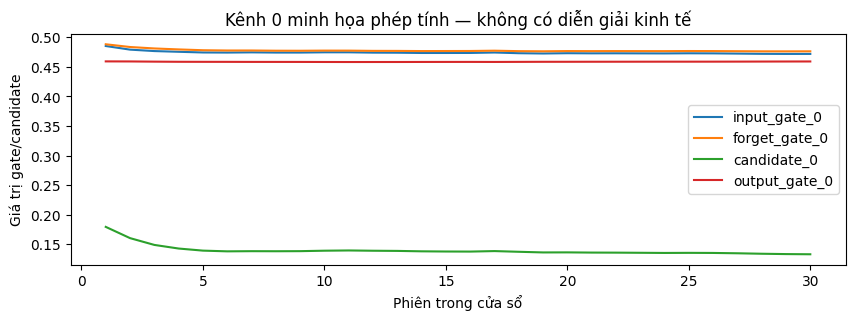

In [9]:
envelope=json.loads((trace_folder/'f5_after_reload.json').read_text(encoding='utf-8'))
trace=envelope['trace']
print(envelope['scope'])
print('Sample:',envelope['sample_id'],'| origin:',envelope['forecast_origin'])
gate_rows=[]
for date,scaled,step in zip(envelope['input_dates'],trace['input_scaled'],trace['steps']):
    gate_rows.append({'time_step':step['time_step'],'input_date':date,'input_scaled':scaled[0],
                     'input_gate_0':step['input_gate'][0],'forget_gate_0':step['forget_gate'][0],
                     'candidate_0':step['candidate_state'][0],'output_gate_0':step['output_gate'][0],
                     'hidden_0':step['hidden_state'][0],'cell_0':step['cell_state'][0]})
gate_table=pd.DataFrame(gate_rows)
display(gate_table)
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(10,3))
for column in ['input_gate_0','forget_gate_0','candidate_0','output_gate_0']:
    ax.plot(gate_table.time_step,gate_table[column],label=column)
ax.set(xlabel='Phiên trong cửa sổ',ylabel='Giá trị gate/candidate',title='Kênh 0 minh họa phép tính — không có diễn giải kinh tế'); ax.legend(); plt.show()

In [10]:
previous=np.asarray(trace['initial_cell'],dtype=np.float64)
for step in trace['steps']:
    i,f,g,o,c,h=[np.asarray(step[k],dtype=np.float64) for k in ['input_gate','forget_gate','candidate_state','output_gate','cell_state','hidden_state']]
    np.testing.assert_allclose(c,f*previous+i*g,rtol=1e-10,atol=1e-12)
    np.testing.assert_allclose(h,o*np.tanh(c),rtol=1e-10,atol=1e-12)
    previous=c
print('Đối chiếu recurrence đủ 30 phiên × 32 chiều đạt.')
display(Markdown('**Giới hạn:** gate là phép tính tái dựng được đối chiếu; JSON schema nội bộ, chưa là API chính thức. Trọng số sau bước tổng hợp không phải model đã học dự báo AAPL.'))

Đối chiếu recurrence đủ 30 phiên × 32 chiều đạt.


**Giới hạn:** gate là phép tính tái dựng được đối chiếu; JSON schema nội bộ, chưa là API chính thức. Trọng số sau bước tổng hợp không phải model đã học dự báo AAPL.

## 5. Môi trường CPU sạch và tái lập
        Notebook này phải chạy bằng `.venv/tv3_clean`, không kế thừa system/user packages. Cell tests ở trên dùng --require-clean: kiểm nguồn imports, lock, torch CPU build, pip-check và không skip.
        Lock68 dependencies nằm trong scripts/requirements-tv3-lock.txt, hướng dẫn docs/TV3_Setup_and_Reproduce.md. Phiên bản ghi ở output là phiên thực chạy, không chép số liệu từ môi trường audit cũ.
        **Local sạch không đồng nghĩa máy thành viên khác.** Cần người nhận xác nhận riêng, không tự gắn tên/kết quả thay họ.

In [11]:
assert test_summary['require_clean'] and test_summary['clean_environment']
assert test_summary['user_site_enabled'] is False
assert test_summary['cpu_torch_build'] and test_summary['pip_check_exit_code']==0
assert not test_summary['lock_mismatches']
display(pd.DataFrame([{'module':n,'import_source':p} for n,p in test_summary['module_origins'].items()]))
display(pd.DataFrame([{'prefix':test_summary['prefix'],'base_prefix':test_summary['base_prefix'],'user_site':test_summary['user_site_enabled'],'torch_CPU_build':test_summary['cpu_torch_build'],'lock_sha256':test_summary['lock_sha256']}]))
print((test_summary_path.parent/'pip-check.log').read_text(encoding='utf-8'))
print((test_summary_path.parent/'requirements-freeze.txt').read_text(encoding='utf-8'))

,module,import_source
0,torch,D:\learn_DeepLearning\Project_course-work\.ven...
1,numpy,D:\learn_DeepLearning\Project_course-work\.ven...
2,pandas,D:\learn_DeepLearning\Project_course-work\.ven...
3,sklearn,D:\learn_DeepLearning\Project_course-work\.ven...
4,nbformat,D:\learn_DeepLearning\Project_course-work\.ven...
5,nbclient,D:\learn_DeepLearning\Project_course-work\.ven...
6,ipykernel,D:\learn_DeepLearning\Project_course-work\.ven...
7,matplotlib,D:\learn_DeepLearning\Project_course-work\.ven...


,prefix,base_prefix,user_site,torch_CPU_build,lock_sha256
0,D:\learn_DeepLearning\Project_course-work\.ven...,C:\Python313,False,True,b3c2b51dee9b06fc7399fbc81635530d38bcde77abbb1f...


No broken requirements found.

asttokens==3.0.2
attrs==26.1.0
cloudpickle==3.1.2
colorama==0.4.6
comm==0.2.3
contourpy==1.3.3
cycler==0.12.1
debugpy==1.8.22
exchange_calendars==4.13.3
executing==2.3.0
fastjsonschema==2.22.3
filelock==4.2.4
fonttools==4.62.1
fsspec==2026.9.0
iniconfig==2.3.1
ipykernel==7.4.0
ipython==9.17.1
ipython_pygments_lexers==1.1.1
jedi==0.20.1
Jinja2==3.1.6
joblib==1.6.0
jsonschema==4.26.0
jsonschema-specifications==2025.9.1
jupyter_client==8.10.0
jupyter_core==5.9.1
kiwisolver==1.5.0
korean_lunar_calendar==0.4.0
MarkupSafe==3.0.3
matplotlib==3.10.9
matplotlib-inline==0.2.2
mpmath==1.3.0
narwhals==2.28.0
nbclient==0.11.0
nbformat==5.11.1
nest-asyncio2==1.7.4
networkx==3.7
numpy==2.4.4
packaging==26.2
pandas==3.0.6
parso==0.8.7
pillow==11.3.0
pip==25.2
platformdirs==4.13.5
pluggy==1.7.0
prompt_toolkit==3.0.53
psutil==7.2.2
pure_eval==0.2.4
Pygments==2.21.0
pyluach==2.3.0
pyparsing==3.3.2
pytest==9.2.0
python-dateutil==2.9.0.post0
pyzmq==27.2.0
referencing==0.37.0


## 6. Bàn giao source/contract cho TV4 và TV6
        TV4 nhận hai model và X/y float64 để thực hiện training/validation/early stopping; TV6 nhận loader/input-only/trace để tích hợp sau khi có checkpoint thật. Không có weights AAPL đã train trong gói này.
        Checkpoint loader kiểm identity/hash/dtype/horizon và mặc định từ chối trained=False. Metadata training do TV4 chịu trách nhiệm; JSON không chứng minh đã train. Xem docs/TV3_Handoff_TV4_TV6.md.
        Cell sau kiểm gói cụ thể và receipt verify sau giải nén. Notebook source được bảo vệ bằng hash cells, outputs được phép cập nhật; chưa xác nhận người nhận trên máy khác.

In [12]:
from scripts.verify_tv3_handoff import verify_members
if (ROOT/'HANDOFF_TV3.json').is_file():
    handoff_root=ROOT
    handoff=json.loads((ROOT/'HANDOFF_TV3.json').read_text(encoding='utf-8'))
    package_info={'handoff_id':handoff['handoff_id'],'archive_sha256':'Xem checksum ZIP riêng do người gửi cung cấp'}
else:
    receipts=sorted((ROOT/'logs/audit').glob('tv3_package_*/summary.json'))
    assert receipts, 'Cần tạo và verify gói TV3 trước khi chạy mục6.'
    package_info=json.loads(receipts[-1].read_text(encoding='utf-8'))
    assert hashlib.sha256(Path(package_info['archive']).read_bytes()).hexdigest()==package_info['archive_sha256']
    handoff_root=Path(package_info['bundle_root'])
    handoff=json.loads((handoff_root/'HANDOFF_TV3.json').read_text(encoding='utf-8'))
verify_members(handoff_root,handoff)
verified=[]
paths=list((ROOT/'logs/audit').glob('tv3_handoff_repro_*/verify_summary.json'))+list((ROOT/'logs/audit').glob('tv3_handoff_verify_*/summary.json'))
for path in paths:
    value=json.loads(path.read_text(encoding='utf-8'))
    if value.get('handoff_id')==handoff['handoff_id'] and value.get('passed'): verified.append((path,value))
assert verified, 'Cần chạy verify_tv3_handoff.py từ bản giải nén trước.'
verify_path,verify_result=sorted(verified,key=lambda pair:str(pair[0]))[-1]
assert handoff['trained_checkpoints']==[]
display(pd.DataFrame(handoff['model_configs']))
display(pd.DataFrame([{'handoff_id':handoff['handoff_id'],'ZIP_SHA256':package_info['archive_sha256'],'local_verify':verify_result['passed'],'trained_checkpoints':len(handoff['trained_checkpoints']),'recipient_machine_verified':verify_result['recipient_machine_verified']}]))
print('Verify evidence:',verify_path)
display(Markdown('**Bàn giao kỹ thuật local đạt. Chưa có checkpoint train AAPL; chưa tự đánh dấu TV4/TV6 đã nhận hoặc máy khác đã chạy.**'))

,model_class,hidden_size,lookback,forecast_length
0,LSTMOneStep,32,30,1
1,LSTMMultiStep,32,30,5


,handoff_id,ZIP_SHA256,local_verify,trained_checkpoints,recipient_machine_verified
0,TV3_Handoff_20261123T032109345167Z,bf121e8f1f07ef2860f35b67471260abb5037ad8e4be7b...,True,0,False


Verify evidence: D:\learn_DeepLearning\Project_course-work\logs\audit\tv3_handoff_repro_20261123T032140745602Z\verify_summary.json


**Bàn giao kỹ thuật local đạt. Chưa có checkpoint train AAPL; chưa tự đánh dấu TV4/TV6 đã nhận hoặc máy khác đã chạy.**

In [13]:
display(pd.DataFrame([{'item':i,'work':w,'status':s} for i,w,s in [(1,'Layout/import/model modules','Đạt local'),(2,'TV2 adapter/float64 identity','Đạt local'),(3,'Model acceptance','Đạt local'),(4,'Trace acceptance','Đạt local'),(5,'Clean environment/reproduce','Đạt local'),(6,'Source/contract handoff','Đạt kỹ thuật local; chờ người nhận/checkpoint thật')]]))
display(Markdown('**Giới hạn:** chưa xác nhận máy khác, không train/tuning/metric AAPL trong notebook này.'))

,item,work,status
0,1,Layout/import/model modules,Đạt local
1,2,TV2 adapter/float64 identity,Đạt local
2,3,Model acceptance,Đạt local
3,4,Trace acceptance,Đạt local
4,5,Clean environment/reproduce,Đạt local
5,6,Source/contract handoff,Đạt kỹ thuật local; chờ người nhận/checkpoint ...


**Giới hạn:** chưa xác nhận máy khác, không train/tuning/metric AAPL trong notebook này.